In [5]:
from logging import warning


class MP_Module:
    def __init__(self, training_x, training_y, test_x, test_y, printing = True, plotting = True):
        self.model = None
        self.training_x = training_x
        self.training_y = training_y
        self.test_x = test_x
        self.test_y = test_y

        self.predicted_y = None
        self.predicted_prob = None

        self.printing = printing
        self.plotting = plotting

    def validation(self, x_original_training_set):
        warning("Validation not implemented")

    def fit(self):
        self.model.fit(self.training_x, self.training_y)

    def predict(self):
        self.predicted_y = self.model.predict(self.test_x)
        return self.predicted_y

    def predict_prob(self):
        self.predicted_prob = self.model.predict_proba(self.test_x)
        return self.predicted_prob

    def transform(self, x_test):
        warning("Transform not implemented")

    def evaluate(self):
        pass

In [6]:
import numpy as np
from matplotlib import pyplot as plt

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


class KNN_MP_Module(MP_Module):
    def __init__(self, training_x, training_y, test_x, test_y, printing=True, plotting=True):
        super().__init__(training_x, training_y, test_x, test_y, printing, plotting)
        self.optimal_k = None

    def validation(self, x_original_training_set):
        # Trovo il K usando la cross-validation
        k_range = range(1, 25)
        k_scores = []

        if self.printing: print("Cross Validation per K in KNN")

        # Provo a usare una pipeline per standardizzare i dati
        # su ogni fold invece che sul training set completo
        for k in k_range:
            knn_cv = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=k))
            scores = cross_val_score(knn_cv, x_original_training_set, self.training_y, cv=10, scoring="accuracy")
            # Voglio monitorare gli scores per ogni K
            if self.printing: print(f"K = {k} ha dato valori di Accuracy pari a: {np.array2string(scores, precision=3)}")
            k_scores.append(scores.mean())

        # Scelgo il K con lo score migliore
        optimal_k = k_range[np.argmax(k_scores)]
        if self.printing:
            print(f"Il K ottimale è {optimal_k}. La massima accuratezza media è: {k_scores[optimal_k-1]:.4f}")

        if self.plotting:
            plt.plot(k_range, k_scores)
            plt.xlabel("K")
            plt.ylabel("Accuratezza media con Cross Validation")
            plt.title("Accuracy media in funzione di K")
            plt.show()

        self.optimal_k = optimal_k

    def fit(self):
        self.model = KNeighborsClassifier(n_neighbors=self.optimal_k)
        super().fit()

    def evaluate(self):
        if self.printing:
            accuracy = accuracy_score(self.test_y, self.predicted_y)
            print(f"Accuracy sul Test Set (K={self.optimal_k}, vicini valutati uniformemente) : {accuracy:.4f}")
            print("\nReport: ", classification_report(self.test_y, self.predicted_y))
            print("\nConfusion Matrix: \n", confusion_matrix(self.test_y, self.predicted_y))

In [7]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import pandas as pd


class SVC_MP_Module(MP_Module):
    def __init__(self, training_x, training_y, test_x, test_y, printing=True, plotting=True):
        super().__init__(training_x, training_y, test_x, test_y, printing, plotting)

    def validation(self, x_original_training_set):
        svc_cv = make_pipeline(
            StandardScaler(),
            SVC()
        )

        param_grid = {
            "svc__C": [0.1, 1, 10, 100],
            "svc__gamma": ["scale", 0.01, 0.1, 1]
        }

        # Per la validation uso la grid-search perchè ho pochi
        # iperparametri da tunare
        grid_search = GridSearchCV(
            estimator=svc_cv,
            param_grid=param_grid,
            cv=5,
            scoring="accuracy",
            n_jobs=-1,
            refit=False,
        )

        # Validation per gli iperparametri
        grid_search.fit(
            x_original_training_set,
            self.training_y
        )

        best_params = grid_search.best_params_

        if self.printing:
            print("Migliori parametri:", best_params)
            print("Accuracy media CV:", grid_search.best_score_)

        svc_pipeline = make_pipeline(
            StandardScaler(),
            SVC(
                C=best_params["svc__C"],
                gamma=best_params["svc__gamma"],
                random_state=99
            )
        )

        # Qui e nel costruttore mi sono appoggiato alla documentazione dell'SVC di scikit-learn
        # perchè usavo SVC(probability=true) così da avere le probabilità per la ROC AUC.
        # Il parametro però veniva segnalato come deprecato, ho quindi usato CalibratedClassifierCV
        # come consigliato nel warning
        # Configuro la calibrazione delle probabilità tramite CV a 5 fold.
        # Questa procedura viene eseguita durante fit() e non seleziona
        # ulteriormente gli iperparametri C e gamma.
        self.model = CalibratedClassifierCV(
            estimator=svc_pipeline,
            method="sigmoid",
            cv=5,
            ensemble=False
        )

    def evaluate(self):
        if self.printing:
            accuracy = accuracy_score(self.test_y, self.predicted_y)
            print(f"Accuratezza del Modello: {accuracy * 100:.2f}%")
            print("\nReport: ", classification_report(self.test_y, self.predicted_y))
            print("Confusion Matrix: \n", confusion_matrix(self.test_y, self.predicted_y))

In [8]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree


class RandomForest_MP_Module(MP_Module):
    def __init__(self, training_x, training_y, test_x, test_y, printing=True, plotting=True):
        super().__init__(training_x, training_y, test_x, test_y, printing, plotting)

    def validation(self, x_original_training_set):
        param_grid = {
            "n_estimators": [25, 50, 75, 100],
            "max_depth": [None, 10, 20],
            "min_samples_leaf": [1, 2, 4]
        }

        # Per la validation uso la grid-search perchè ho pochi
        # iperparametri da tunare
        grid_search = GridSearchCV(
            estimator=RandomForestClassifier(
                random_state=99
            ),
            param_grid=param_grid,
            cv=5,
            scoring="accuracy",
            n_jobs=-1,
            refit=False
        )

        grid_search.fit(
            x_original_training_set,
            self.training_y
        )

        if self.printing:
            print("Migliori parametri:", grid_search.best_params_)
            print("Accuracy media CV:", grid_search.best_score_)

        best_n_estimators = grid_search.best_params_["n_estimators"]
        best_max_depth = grid_search.best_params_["max_depth"]
        best_min_samples_leaf = grid_search.best_params_["min_samples_leaf"]

        self.model = RandomForestClassifier(
            n_estimators=best_n_estimators,
            max_depth=best_max_depth,
            min_samples_leaf=best_min_samples_leaf,
            random_state=99
        )

    def evaluate(self):
        # Qui voglio vedere la feature importance basata sulla MDI
        if self.printing:
            feature_importance = pd.Series(self.model.feature_importances_, index=self.training_x.columns).sort_values(ascending=False)
            print(f"\nImportanza delle Feature:\n{feature_importance}")

    def plot_random_tree(self):
        if self.plotting:

            tree_index = np.random.randint(
                0,
                len(self.model.estimators_)
            )

            fig, ax = plt.subplots(figsize=(12, 8))

            plot_tree(
                self.model.estimators_[tree_index],
                feature_names=self.training_x.columns,
                class_names= self.model.classes_,
                max_depth=3,
                filled=True,
                rounded=True,
                fontsize=7,
                ax=ax,
            )

            ax.set_title(f"Albero casuale nella Random Forest. Albero Scelto: {tree_index}")

            plt.tight_layout()
            plt.show()

In [9]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA


sns.set_theme(style="whitegrid")

class MP_PCA_Module:
    def __init__(self, acceptable_cumulative_variance = 0.9, printing = True, plotting=True):
        self.pca = PCA()
        self.acc_cum_v = acceptable_cumulative_variance
        self.training_x = None


        self.printing = printing
        self.plotting = plotting

    def fit(self, x_training):
        self.training_x = x_training
        self.pca.fit(x_training)

    def transform(self, x_to_transform):
        return self.pca.transform(x_to_transform)

    def fit_transform(self, x_to_transform):
        self.training_x = x_to_transform
        return self.pca.fit_transform(x_to_transform)

    def change_components_num(self, new_components_num : int):
        self.pca = PCA(n_components=new_components_num)
        self.fit(self.training_x)

    def change_acceptable_cumulative_variance(self, acceptable_cumulative_variance : float):
        if not 1.0 > acceptable_cumulative_variance > 0.0:
            raise ValueError("La soglia deve essere compresa tra 0 e 1")
        self.acc_cum_v = acceptable_cumulative_variance
        self.pca = PCA(n_components=acceptable_cumulative_variance)
        self.fit(self.training_x)

    def evaluate(self):
        # --- --- Valutazione PCA --- ---
        if self.printing: print(f"Feature originali: {self.training_x.shape[1]}, Componenti mantenute: {self.pca.n_components_}, Soglia di Accettabilità per la Varianza Cumulativa Spiegata: {self.acc_cum_v:.2%}")
        tot_variance = 0
        ideal_variance_flag = False
        ideal_components_num = None
        # Controllo la percentuale di spieghabilità ottenuta da ogni componente
        for i, variance in enumerate(self.pca.explained_variance_ratio_):
            tot_variance += variance
            if ideal_variance_flag == False and tot_variance >= self.acc_cum_v:
                ideal_variance_flag = True
                if self.printing: print(f"Varianza PC{i + 1}: {variance:.2%}, Varianza Totale: {tot_variance:.2%} -> Soglia Raggiunta")
                ideal_components_num = i+1
                continue
            if self.printing: print(f"Varianza PC{i + 1}: {variance:.2%}, Varianza Totale: {tot_variance:.2%}")

        cum_variances = self.get_cumulative_variance()
        if self.printing:
            print(f"Varianza totale spiegata: {cum_variances[-1]:.2%}\n")  # Prendo l'ultimo elemento, che contiene la somma totale
            print(f"Numero di componenti ideale identificato in {ideal_components_num}")
        return ideal_components_num

    def get_cumulative_variance(self):
        return np.cumsum(self.pca.explained_variance_ratio_)

    def plot_cumulative_variance_with_threshold(self):
        cum_variances = self.get_cumulative_variance()

        # Creo le X del mio grafico, corrispondenti alle varie possibili quantità di componenti
        pca_components_n = np.arange(
            1,
            len(cum_variances) + 1
        )

        if self.plotting:
            # Siccome ho più di 3 dimensioni vado a stampare solo la percentuale di varianza spiegata
            # Da questo Scree Plot ottengo le stesse informazioni della mia evaluation esposta tramite prints sul terminale
            plt.figure(figsize=(10, 8))
            plt.plot(pca_components_n, cum_variances, marker="o", linestyle="--")
            plt.xlabel("Numero di Componenti")
            plt.ylabel("Varianza Spiegata Cumulativa")
            plt.axhline(y=self.acc_cum_v, linestyle="--")
            plt.title("Scree Plot - Dry Bean - Varianza Spiegata con PCA")
            plt.show()

    # Mostro la tabella che spiega quanto ogni feature contribuisce su ogni componente principale della PCA
    def feature_to_component_evaluation(self, plot_size=(12,9)):
        if not self.plotting: return

        indexes = []
        for i in range(self.pca.n_components_):
            indexes.append(f"PC{i+1}")

        pca_feature_on_comp_weights = pd.DataFrame(
            self.pca.components_,
            columns=self.training_x.columns,
            index = indexes
        )

        fig, ax = plt.subplots(figsize=plot_size)

        sns.heatmap(
            pca_feature_on_comp_weights,
            annot=True,
            cmap="coolwarm",
            center=0,
            fmt=".2f",
            ax=ax,
            square=False,
            annot_kws={"size": 11}
        )

        ax.set_title("Coefficienti delle feature nelle componenti PCA", pad=20)
        ax.set_xlabel("Feature originali")
        ax.set_ylabel("Componenti principali")

        # Ho provato a usare la funzione tight_layout su di un normale plot, ma ottenevo una visualizzazione
        # troppo piccola, mentre senza ottenevo nomi delle feature graficamente tagliati
        # Ho quindi provato a usare una rotazione delle etichette e il risultato è decente

        # Etichette ruotate di 45 gradi
        ax.tick_params(axis="x", labelrotation=45)

        # Allineamento delle etichette
        plt.setp(
            ax.get_xticklabels(),
            ha="right",
            rotation_mode="anchor"
        )

        # Gestisco i margini dell'immagine per garantire abbastanza spazio alle etichette
        # e al titolo
        fig.subplots_adjust(
            left=0.08,
            right=0.96,
            top=0.91,
            bottom=0.23
        )

        plt.show()

    def plot_components_2d(self, x_pca, y_pca, plot_size=(12, 8)):
        if not self.plotting: return

        df_plot = pd.DataFrame({
            "PC1": x_pca[:, 0],
            "PC2": x_pca[:, 1],
            "Quality": np.asarray(y_pca).ravel()
        })

        plt.figure(figsize=plot_size)

        sns.scatterplot(
            data=df_plot,
            x="PC1",
            y="PC2",
            hue="Quality",
            alpha=0.65
        )

        plt.title("Distribuzione nello spazio PC1-PC2")
        variance = self.pca.explained_variance_ratio_

        plt.xlabel(f"PC1 - {variance[0]:.2%} della varianza")
        plt.ylabel(f"PC2 - {variance[1]:.2%} della varianza")

        plt.tight_layout()
        plt.show()

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

############## PUNTO 3 - Metriche di Valutazione ##############

class ClassificationMetrics_MP_Module:
    def __init__(self, y_true, y_pred, classificator_name : str):
        self.y_true = np.asarray(y_true).ravel()
        self.y_pred = np.asarray(y_pred).ravel()
        self.classificator_name = classificator_name

        self.classes = np.unique(
            np.concatenate([self.y_true, self.y_pred])
        )

        # Potrei implementarla più dalle fondamenta, eventualmente TO-DO
        self.confusion_matrix = self.calculate_confusion_matrix()

        self.report = None
        self.accuracy = None

    def evaluate(self):
        results = []

        total = np.sum(self.confusion_matrix)
        correct = np.trace(self.confusion_matrix)

        self.accuracy = correct / total

        for i, class_name in enumerate(self.classes):
            # TP = Valori sulla diagonale della matrice
            true_positive   = self.confusion_matrix[i, i]
            # FP = Sommo i valori sulla colonna e tolgo i valori della diagonale
            false_positive  = self.confusion_matrix[:, i].sum() - true_positive
            # FN = Sommo i valori sulla riga e tolgo i valori della diagonale
            false_negative  = self.confusion_matrix[i, :].sum() - true_positive
            # TN = Sottraggo dal totale tutti gli altri indicatori
            true_negative   = total - true_positive - false_positive - false_negative

            precision = true_positive / (true_positive + false_positive) if (true_positive + false_positive) else 0
            recall = true_positive / (true_positive + false_negative) if (true_positive + false_negative) else 0

            f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) else 0

            class_result = {
                "Class": class_name,
                "TP": true_positive,
                "FP": false_positive,
                "FN": false_negative,
                "TN": true_negative,
                "Precision": precision,
                "Recall": recall,
                "F1": f1,
            }

            results.append(class_result)

        self.report = pd.DataFrame(results).set_index("Class")

        return self.report

    def plot_metrics(self):
        if self.report is None:
            raise ValueError("Prima di effettuare plot_metrics bisogna eseguire il metodo evaluate()")

        sns.set_style("white")
        sns.set_context("paper")

        counts = self.report[["TP", "FP", "FN", "TN"]]
        metrics = self.report[["Precision", "Recall", "F1"]]

        fig, axes = plt.subplots(1,2, figsize=(10, 8))

        sns.heatmap(
            counts,
            annot=True,
            fmt="d",
            cmap="Blues",
            ax=axes[0]
        )

        axes[0].set_title("TP, TN, FP, FN per classe")
        axes[0].set_xlabel("Conteggi")
        axes[0].set_ylabel("Classe")

        sns.heatmap(
            metrics,
            annot=True,
            fmt=".3f",
            cmap="Blues",
            vmin=0,
            vmax=1,
            ax=axes[1]
        )

        axes[1].set_title("Precision, Recall e F1")
        axes[1].set_xlabel("Metriche")
        axes[1].set_ylabel("Classe")

        fig.suptitle(f"Valutazione del classificatore {self.classificator_name}", fontsize=16)

        fig.text(
            0.5, 0.92,
            f"Accuracy = {self.accuracy:.2%}",
            ha="center",
            fontsize=12
        )

        plt.show()


############## PUNTO 4 - Plotting Confusion Matrix e ROC AUC Curve ##############
    def calculate_confusion_matrix(self):
        if len(self.y_true) != len(self.y_pred):
            raise ValueError("Le dimensioni dei vettori per le Classi predette e le Classi reali non coincidono")

        num_of_classes = len(self.classes)
        matrix = np.zeros((num_of_classes, num_of_classes), dtype=int)
        class_indexes = {}
        for i, class_name in enumerate(self.classes):
            class_indexes[class_name] = i

        # Preferisco calcolare qui solo i valori per avere la matrice completa
        # e introdurre in un altro punto l'ottenimento dei singoli indicatori
        # ottenibili da essa
        for index in range(len(self.y_true)):
            i = class_indexes[self.y_true[index]]
            j = class_indexes[self.y_pred[index]]

            matrix[i, j] += 1

        return matrix

    def plot_confusion_matrix(self):
        fig, ax = plt.subplots(figsize=(10, 8))

        sns.heatmap(
            self.confusion_matrix,
            annot=True,
            cmap="Blues",
            fmt="d",
            xticklabels=self.classes,
            yticklabels=self.classes,
            ax=ax,
            square=True
        )

        ax.set_title(f"Confusion Matrix del Classificatore {self.classificator_name}")
        ax.set_xlabel("Valori Predetti")
        ax.set_ylabel("Valori Reali")

        plt.tight_layout()
        plt.show()

    def plot_roc_auc(self, y_proba, model_classes):

        fig, ax = plt.subplots(figsize=(10, 8))

        for i, class_name in enumerate(model_classes):
            y_binary = (self.y_true == class_name).astype(int)
            class_scores = y_proba[:, i]

            # Calcolo la ROC per tutte le soglie con il metodo di scikit-learn
            false_positive_rate, true_positive_rate, thresholds = roc_curve(
                y_binary,
                class_scores
            )

            # Calcolo l'area sotto la curva sempre con il metodo di scikit-learn
            roc_auc = auc(false_positive_rate, true_positive_rate)

            ax.plot(
                false_positive_rate,
                true_positive_rate,
                label=f"{class_name} (AUC = {roc_auc:.3f})"
            )

        # Diagonale di riferimento
        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="red",
            label="Classificatore casuale"
        )

        ax.set_title(f"ROC Curve - {self.classificator_name}")
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

        ax.legend(loc="lower right")
        ax.grid()

        plt.tight_layout()
        plt.show()

In [11]:
import numpy as np
import shap
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier


############## PUNTO 5 - SPIEGABILITà ##############
# Utilizzo l'algoritmo Model-Specific TreeSHAP per spiegare il modello Random Forest
# utilizzando come campioni un campione predetto correttamente e uno predetto erroneamente

class SHAP_MP_Module:
    def __init__(self, tree_classifier, training_x, training_y, test_x, test_y, predicted_y, printing = True, plotting = True):
        self.explainer = None
        self.tree_classifier = tree_classifier

        self.training_x = training_x
        self.training_y = training_y
        self.test_x = test_x
        self.test_y = test_y

        self.predicted_y = predicted_y

        self.printing = printing
        self.plotting = plotting

    # Prima avevo implementato lo SHAP su tutti i campioni di test, ma ci metteva abbastanza ad aprirsi.
    # Poi ho letto online che il TreeExplainer è capace di spiegare allo stesso modo sulla base di singoli
    # campioni se il modello di scikit-learn passatogli è già stato addestrato
    # Ipotizzo che non cambi molto allo scopo dell'elaborato
    def explain_tree(self):
        if not self.plotting:
            print("Modulo impostato come non-plotting.")
            return

        # Individuo le predizioni corrette ed errate
        correct_predictions = np.where(self.test_y.to_numpy() == self.predicted_y)[0]
        wrong_predictions = np.where(self.test_y.to_numpy() != self.predicted_y)[0]

        if correct_predictions.size == 0:
            print("Il dataset manca di predizioni corrette")
            return
        if wrong_predictions.size == 0:
            print("Il dataset manca di predizioni errate")
            return

        # Seleziono un campione corretto e uno errato
        records_to_explain = [correct_predictions[0], wrong_predictions[0]]

        self.explainer = shap.TreeExplainer(self.tree_classifier)

        # Calcolo SHAP per una predizione corretta e una errata
        selected_samples = self.test_x.iloc[records_to_explain]
        shap_values = self.explainer(selected_samples)

        # Visualizzo i grafici waterfall
        for i, record_index in enumerate(records_to_explain):

            real_class = self.test_y.iloc[record_index]
            predicted_class = self.predicted_y[record_index]

            class_index = list(self.tree_classifier.classes_).index(predicted_class)

            prediction_status = (
                "CORRETTA"
                if real_class == predicted_class
                else "ERRATA"
            )

            shap.plots.waterfall(
                shap_values[i, :, class_index],
                max_display=self.test_x.shape[1],
                show=False
            )

            fig = plt.gcf()
            fig.set_size_inches(14, 9)

            fig.suptitle(
                f"Spiegazione SHAP - Predizione {prediction_status}\n"
                f"Campione: {record_index}, Classe reale: {real_class} - Classe predetta: {predicted_class}"
            )

            fig.subplots_adjust(
                left=0.30,
                right=0.95,
                top=0.90,
                bottom=0.10
            )

            plt.show()

Dimensioni X_train: (9527, 16)
Dimensioni X_test: (4084, 16)

PCA SECTION

Valutazione PCA
Feature originali: 16, Componenti mantenute: 16, Soglia di Accettabilità per la Varianza Cumulativa Spiegata: 92.00%
Varianza PC1: 55.35%, Varianza Totale: 55.35%
Varianza PC2: 26.41%, Varianza Totale: 81.77%
Varianza PC3: 8.09%, Varianza Totale: 89.86%
Varianza PC4: 5.14%, Varianza Totale: 94.99% -> Soglia Raggiunta
Varianza PC5: 2.77%, Varianza Totale: 97.76%
Varianza PC6: 1.15%, Varianza Totale: 98.91%
Varianza PC7: 0.70%, Varianza Totale: 99.60%
Varianza PC8: 0.33%, Varianza Totale: 99.93%
Varianza PC9: 0.05%, Varianza Totale: 99.98%
Varianza PC10: 0.01%, Varianza Totale: 99.99%
Varianza PC11: 0.01%, Varianza Totale: 100.00%
Varianza PC12: 0.00%, Varianza Totale: 100.00%
Varianza PC13: 0.00%, Varianza Totale: 100.00%
Varianza PC14: 0.00%, Varianza Totale: 100.00%
Varianza PC15: 0.00%, Varianza Totale: 100.00%
Varianza PC16: 0.00%, Varianza Totale: 100.00%
Varianza totale spiegata: 100.00%

Nu

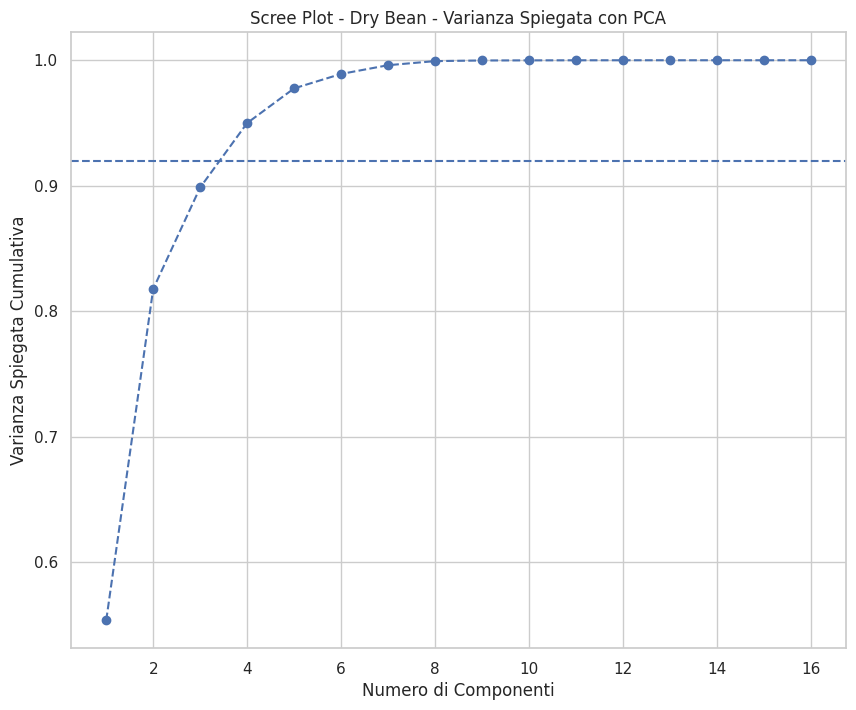

Esecuzione PCA
Feature originali: 16, Componenti mantenute: 4, Soglia di Accettabilità per la Varianza Cumulativa Spiegata: 92.00%
Varianza PC1: 55.35%, Varianza Totale: 55.35%
Varianza PC2: 26.41%, Varianza Totale: 81.77%
Varianza PC3: 8.09%, Varianza Totale: 89.86%
Varianza PC4: 5.14%, Varianza Totale: 94.99% -> Soglia Raggiunta
Varianza totale spiegata: 94.99%

Numero di componenti ideale identificato in 4


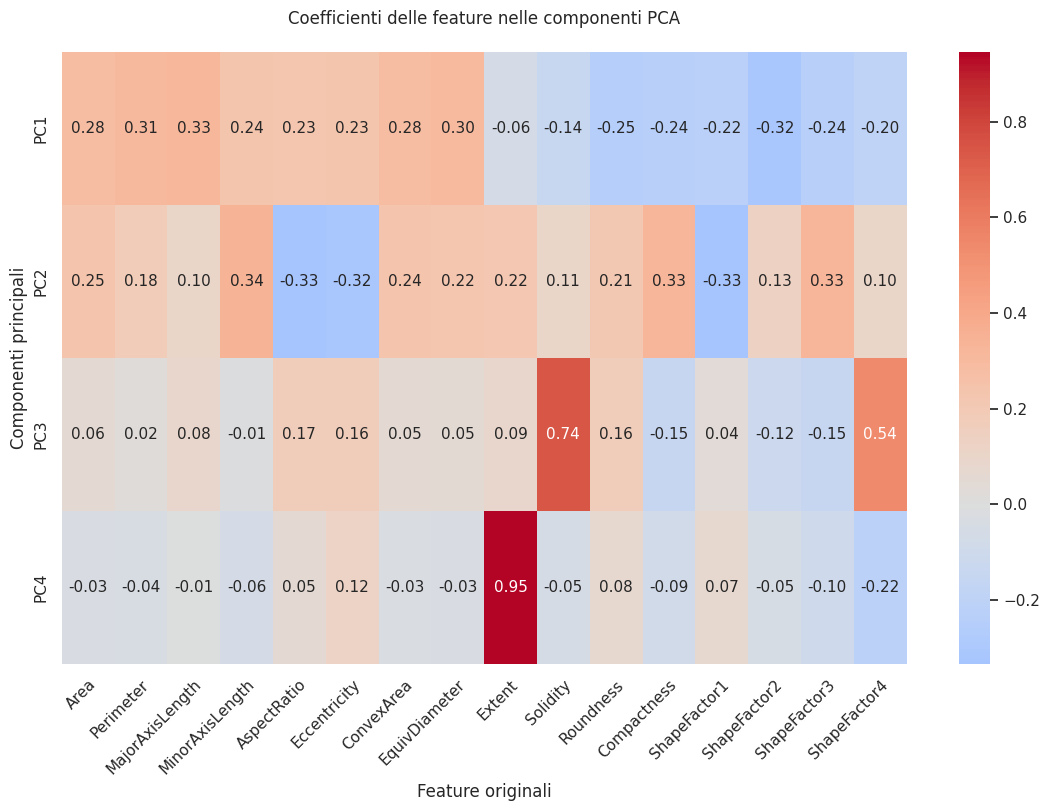

Dimensioni del Training Set con PCA: (9527, 4)
Dimensioni del Test Set con PCA: (4084, 4)


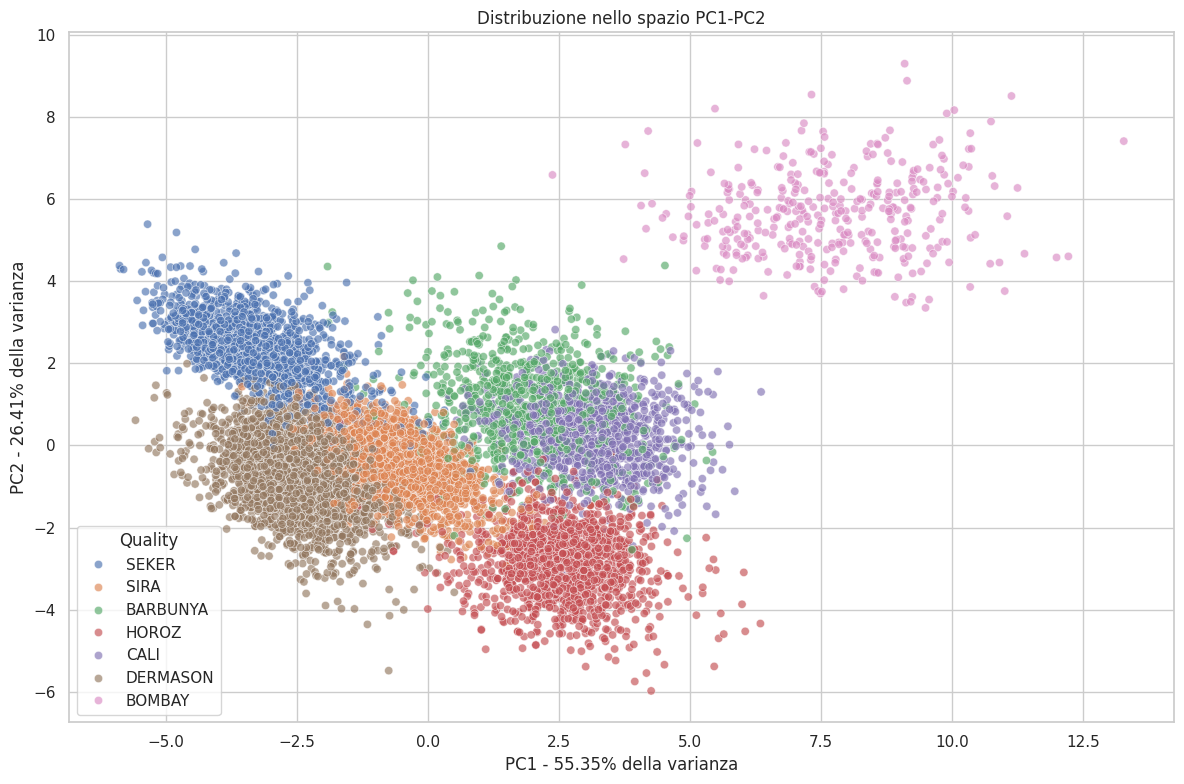


K NEAREST NEIGHBOR SECTION

Cross Validation per K in KNN
K = 1 ha dato valori di Accuracy pari a: [0.903 0.894 0.905 0.927 0.907 0.913 0.906 0.899 0.896 0.91 ]
K = 2 ha dato valori di Accuracy pari a: [0.903 0.895 0.906 0.913 0.906 0.895 0.899 0.895 0.892 0.901]
K = 3 ha dato valori di Accuracy pari a: [0.914 0.91  0.917 0.932 0.915 0.919 0.914 0.909 0.891 0.931]
K = 4 ha dato valori di Accuracy pari a: [0.921 0.916 0.92  0.935 0.915 0.924 0.919 0.912 0.901 0.921]
K = 5 ha dato valori di Accuracy pari a: [0.919 0.913 0.911 0.935 0.918 0.93  0.929 0.918 0.898 0.934]
K = 6 ha dato valori di Accuracy pari a: [0.917 0.916 0.908 0.934 0.925 0.921 0.928 0.916 0.907 0.924]
K = 7 ha dato valori di Accuracy pari a: [0.924 0.917 0.908 0.937 0.931 0.93  0.931 0.914 0.915 0.928]
K = 8 ha dato valori di Accuracy pari a: [0.921 0.916 0.906 0.938 0.929 0.93  0.924 0.913 0.91  0.934]
K = 9 ha dato valori di Accuracy pari a: [0.921 0.912 0.914 0.936 0.925 0.931 0.928 0.911 0.903 0.934]
K = 10 ha dato

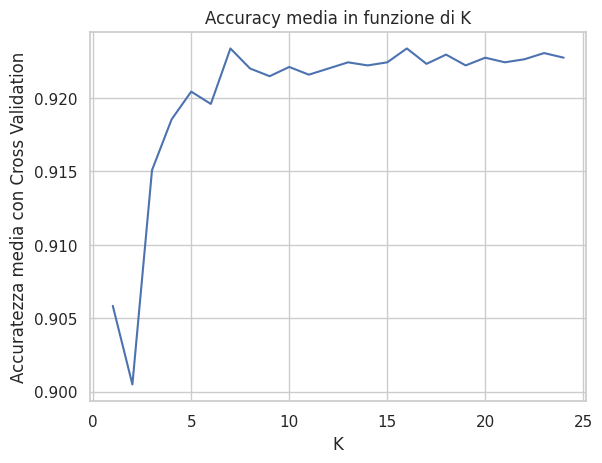

Accuracy sul Test Set (K=16, vicini valutati uniformemente) : 0.9238

Report:                precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.93      0.94      0.94       489
    DERMASON       0.92      0.92      0.92      1064
       HOROZ       0.96      0.95      0.96       578
       SEKER       0.95      0.95      0.95       608
        SIRA       0.86      0.89      0.87       791

    accuracy                           0.92      4084
   macro avg       0.94      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084


Confusion Matrix: 
 [[349   0  26   0   2   2  18]
 [  0 157   0   0   0   0   0]
 [ 15   0 461   0   5   1   7]
 [  0   0   0 979   2  19  64]
 [  1   0   9   9 548   0  11]
 [  2   0   0  11   1 575  19]
 [  0   0   0  69  10   8 704]]


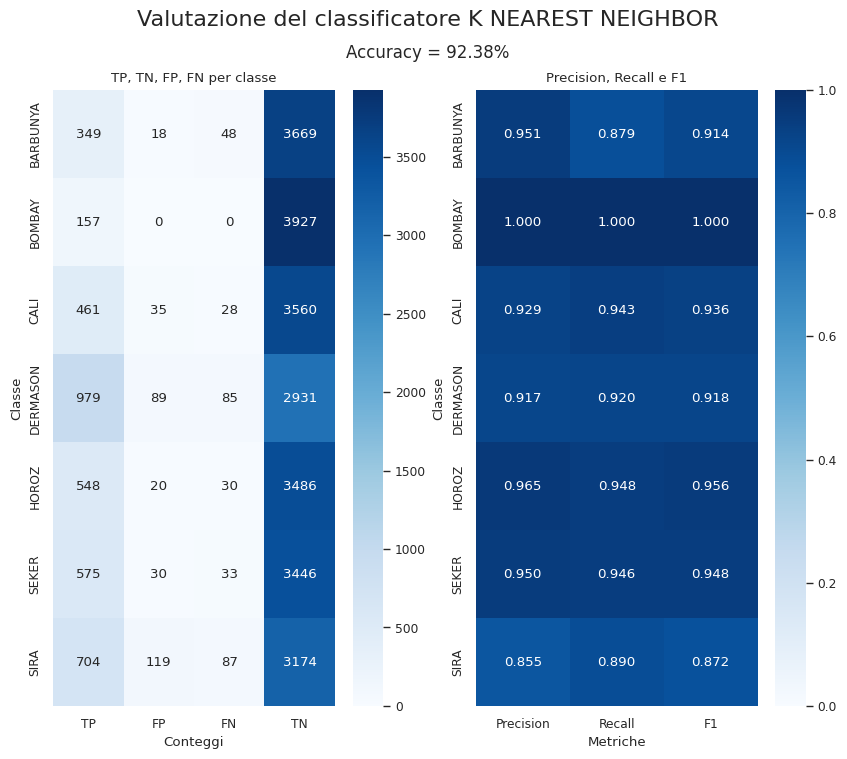

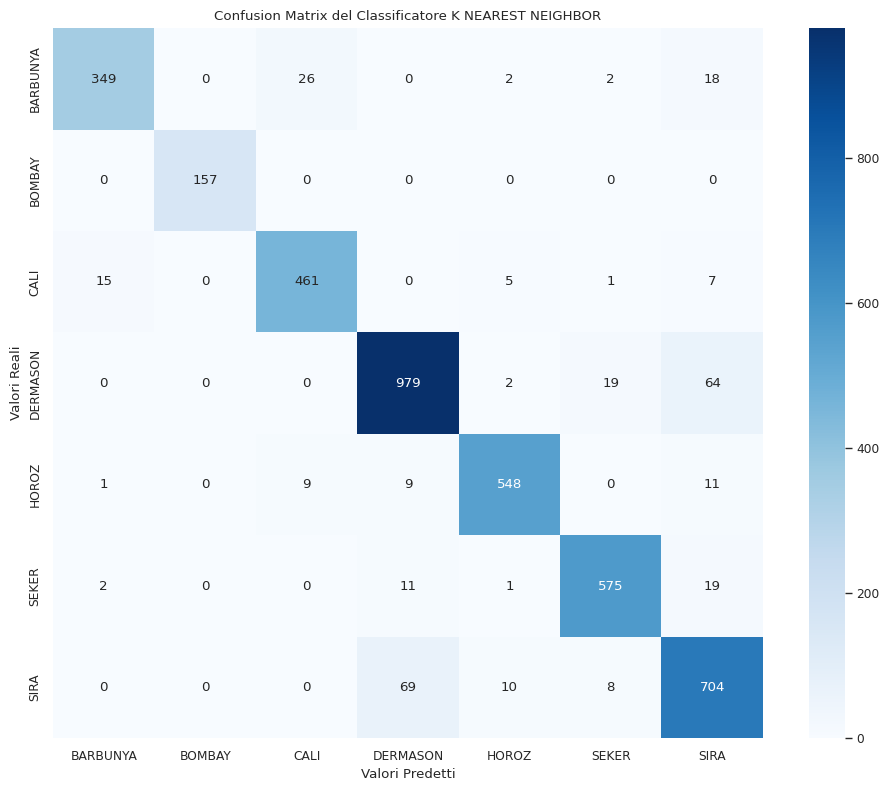

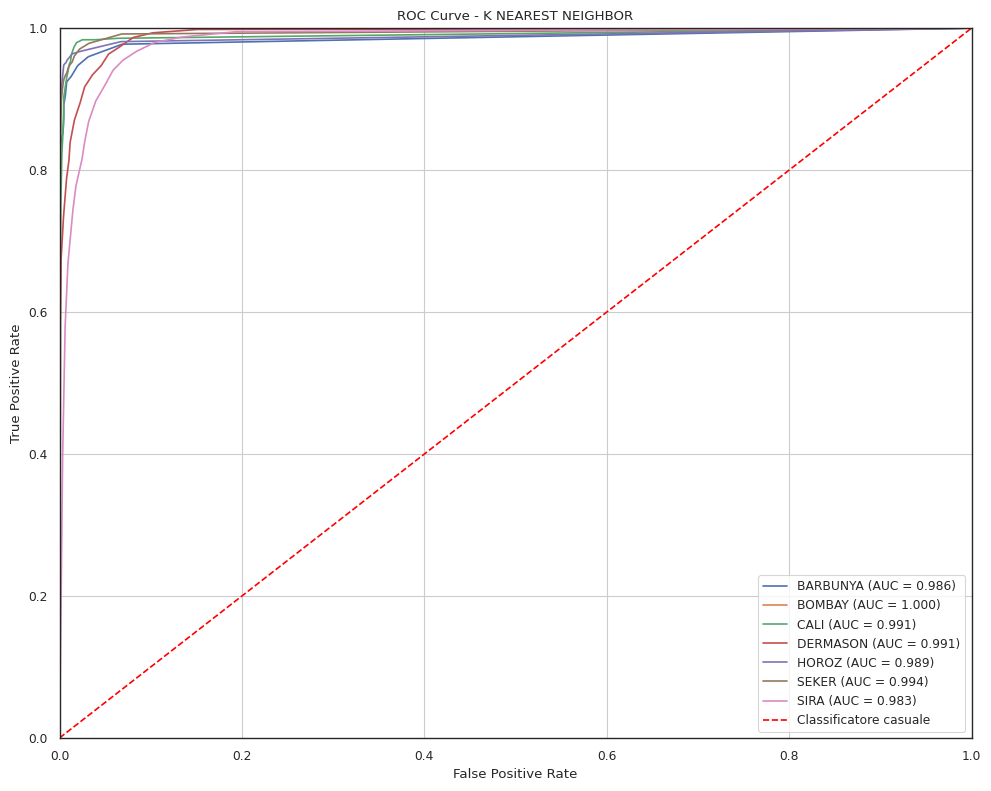


RANDOM FOREST SECTION

Migliori parametri: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 50}
Accuracy media CV: 0.9216965901298014

Importanza delle Feature:
Compactness        0.112325
ConvexArea         0.105949
ShapeFactor1       0.095924
ShapeFactor3       0.085408
MajorAxisLength    0.073886
Eccentricity       0.072706
Perimeter          0.069884
EquivDiameter      0.066841
MinorAxisLength    0.061363
Area               0.060845
Roundness          0.054953
AspectRatio        0.054240
ShapeFactor2       0.041682
ShapeFactor4       0.024085
Solidity           0.012549
Extent             0.007361
dtype: float64


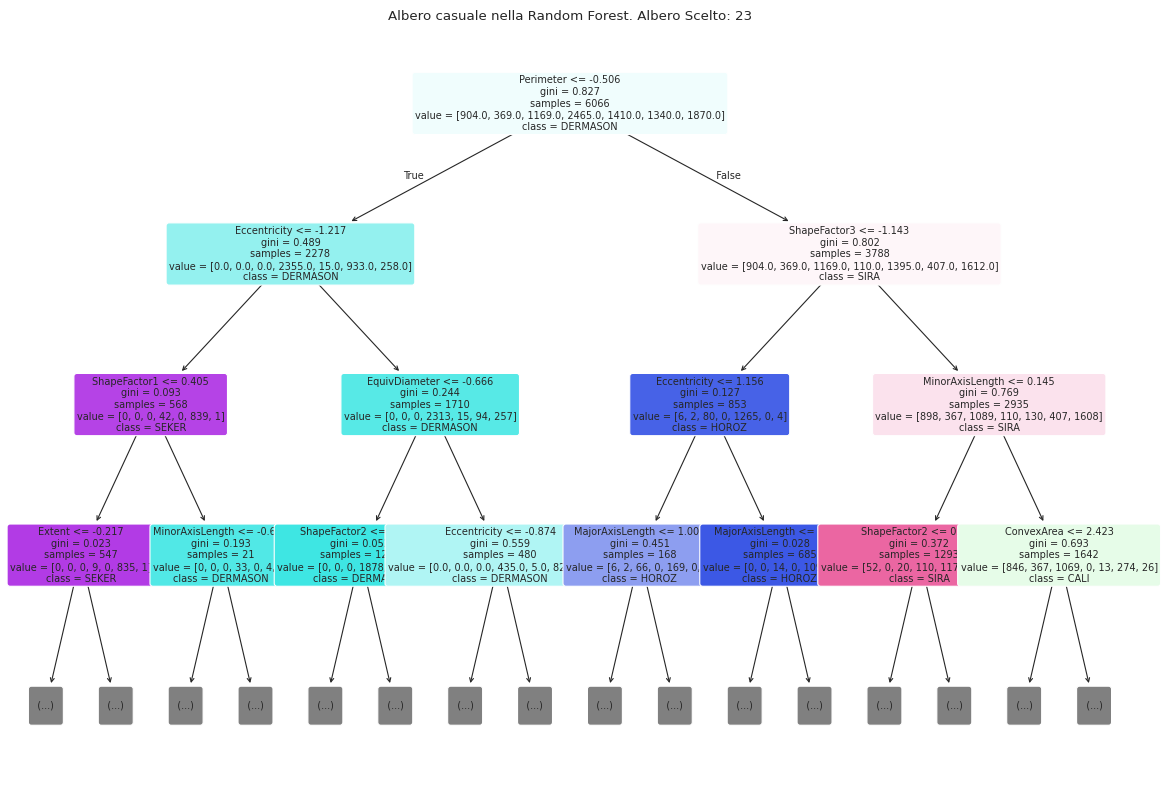

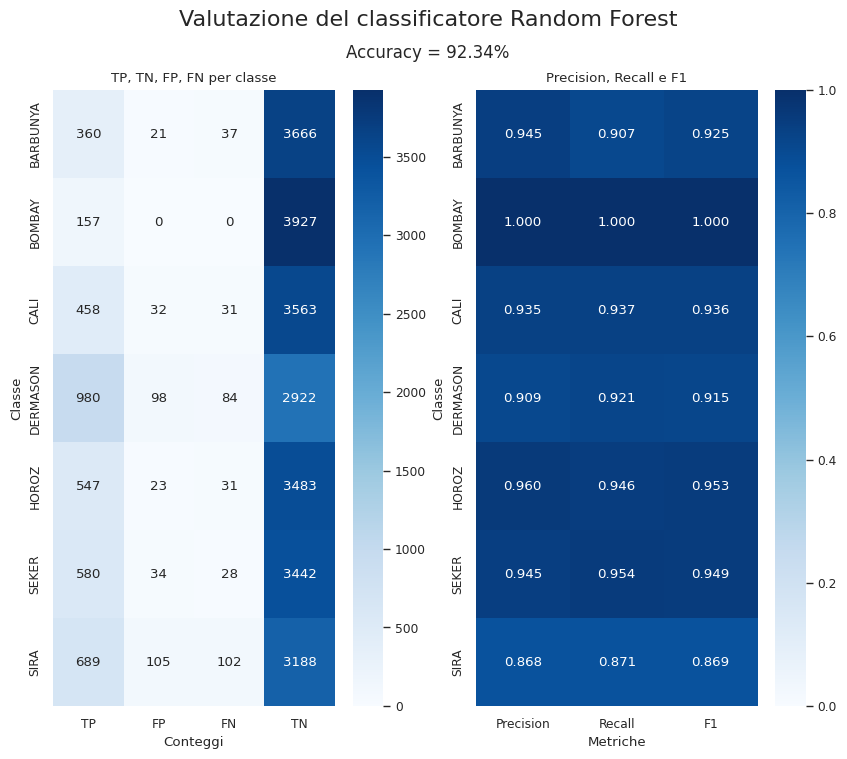

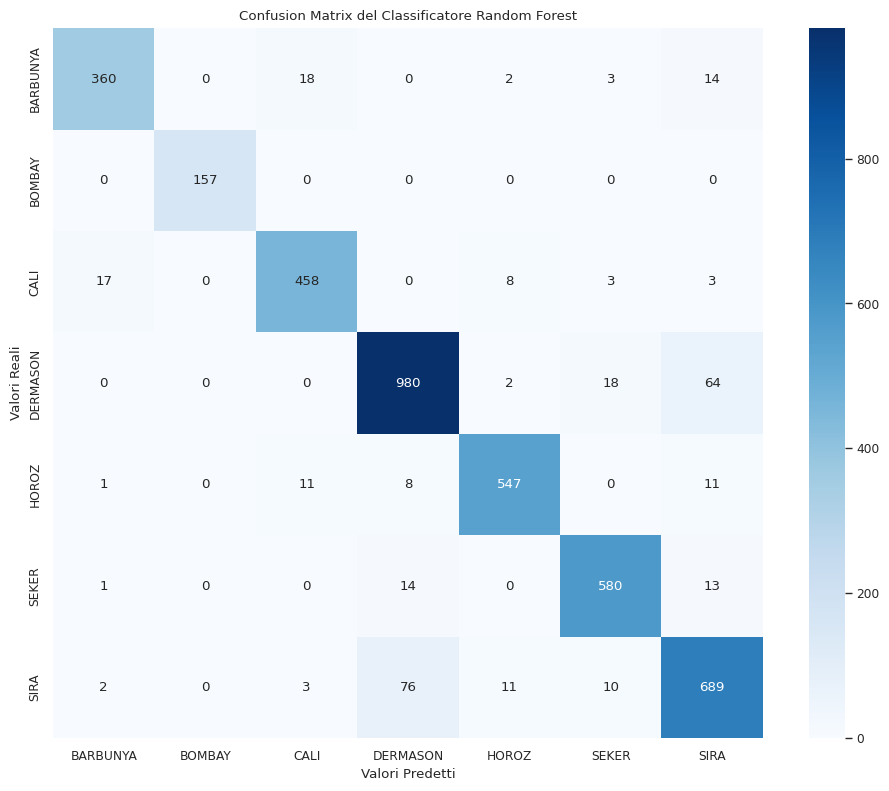

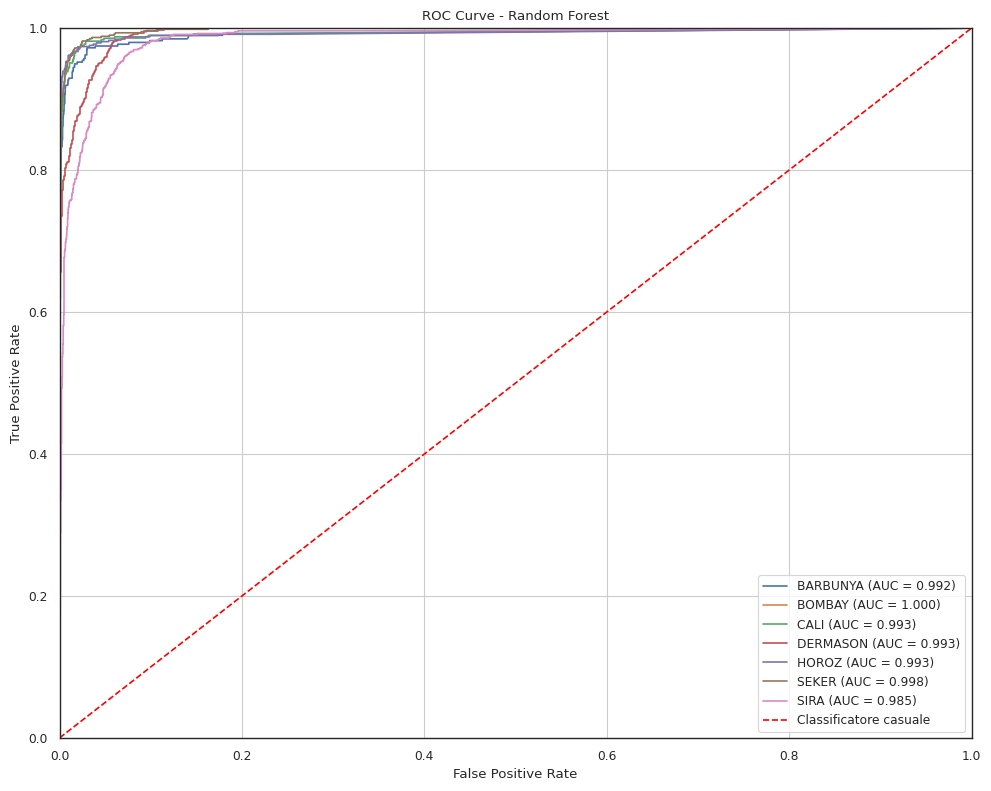

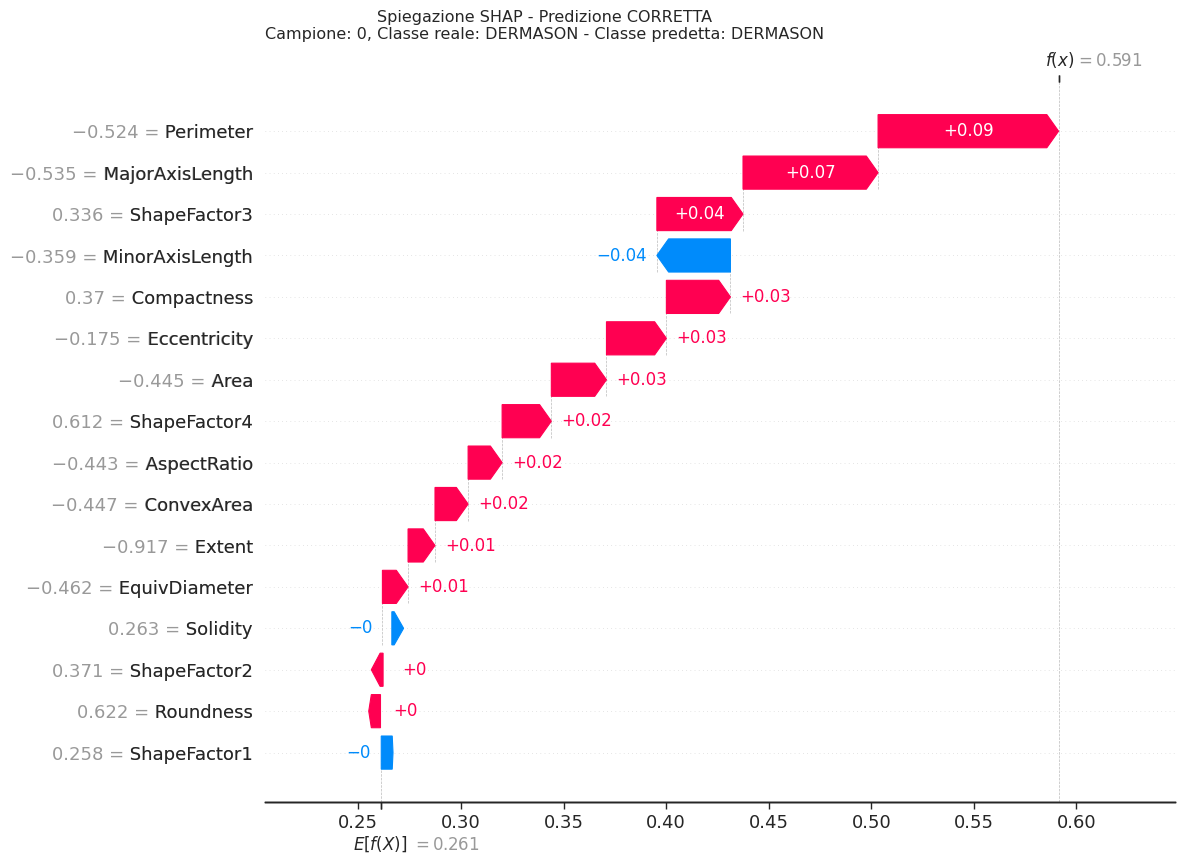

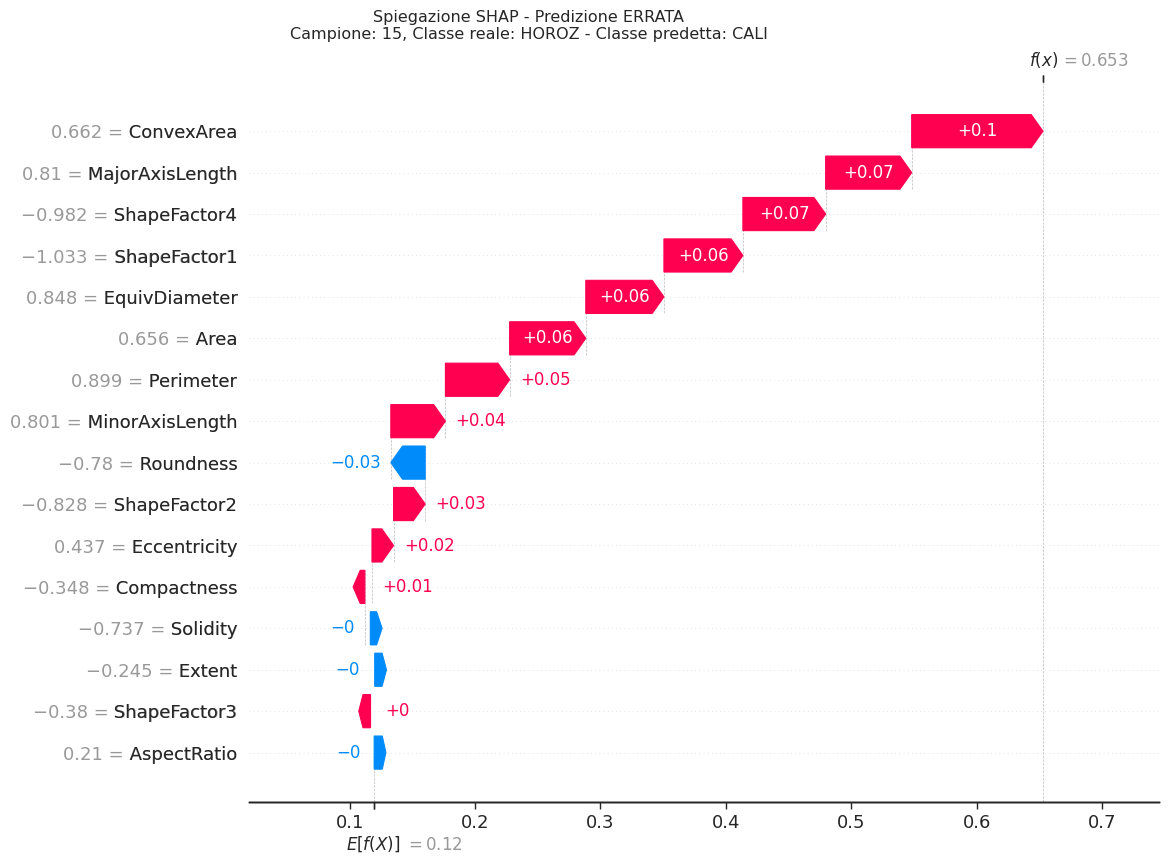


SVM SECTION

Migliori parametri: {'svc__C': 10, 'svc__gamma': 0.1}
Accuracy media CV: 0.9304090687509812
Accuratezza del Modello: 93.22%

Report:                precision    recall  f1-score   support

    BARBUNYA       0.95      0.92      0.94       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.96      0.95      0.96       489
    DERMASON       0.92      0.93      0.92      1064
       HOROZ       0.97      0.94      0.96       578
       SEKER       0.95      0.95      0.95       608
        SIRA       0.87      0.89      0.88       791

    accuracy                           0.93      4084
   macro avg       0.95      0.94      0.94      4084
weighted avg       0.93      0.93      0.93      4084

Confusion Matrix: 
 [[366   0  12   0   2   3  14]
 [  0 157   0   0   0   0   0]
 [ 13   0 466   0   4   2   4]
 [  0   0   0 986   1  17  60]
 [  3   0   7  10 545   0  13]
 [  2   0   0   8   1 580  17]
 [  1   0   0  69   7   7 707]]


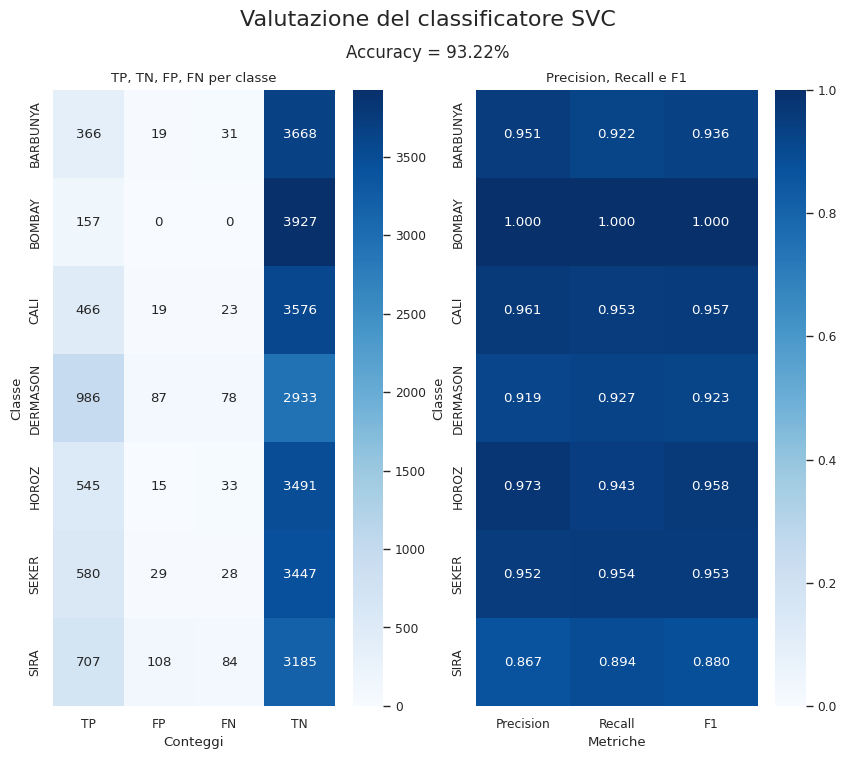

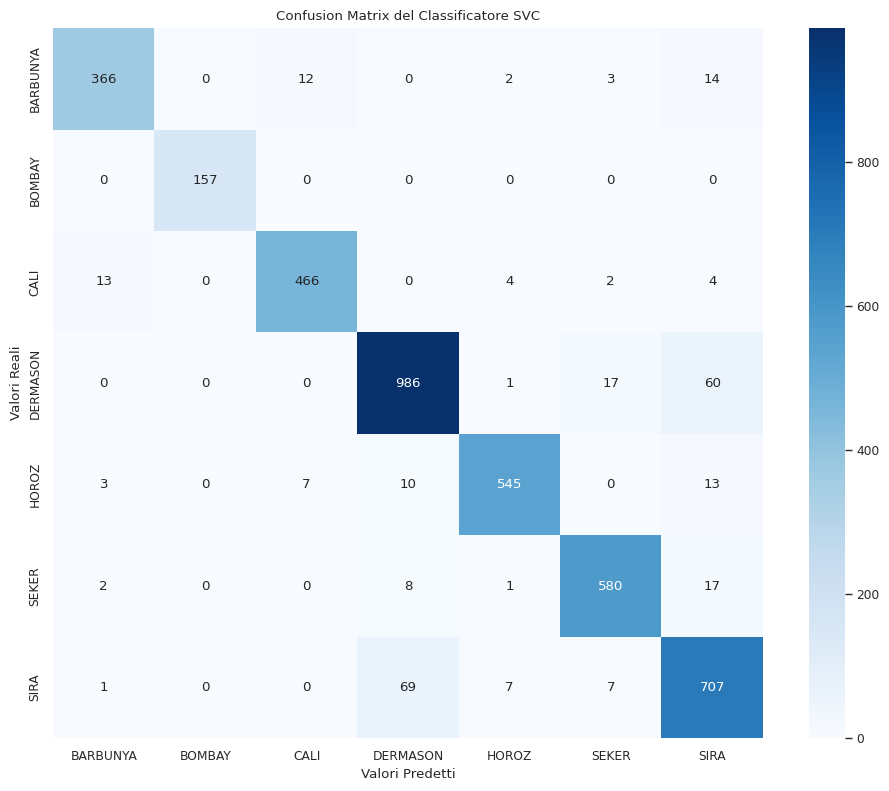

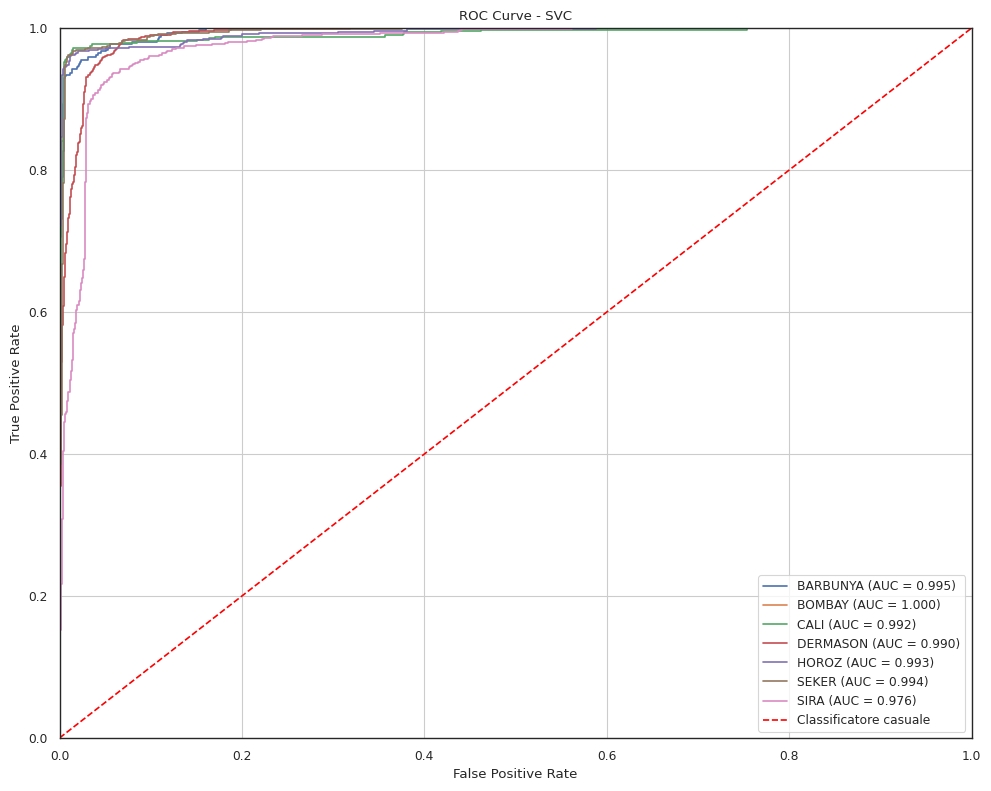

In [12]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd
import shap
from matplotlib import pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Gli import dei moduli locali sono stati rimossi poiché le classi
# sono già state definite ed eseguite nelle celle precedenti del notebook.

########################### PUNTO 0 - NOTE INIZIALI ###########################
# Per amore della modularità cerco di dividere l'utilizzo dei modelli del mio progetto
# in diversi oggetti che sfruttano i modelli che abbiamo studiato a lezione.
# Sto sviluppando in PyCharm quindi le cose potrebbero venir cambiate una volta spostato su Google Coolab

# Ho scelto il dataframe Dry Bean dopo aver provato ad utilizzare Mushroom(id=73) e Wine Quality(id=186), che però
# sembravano non prestarsi ad algoritmi shallow di classificazione.
# Wine Quality aveva delle classi molto sovrapposte che rendevano difficile la catalogazione,
# Mushroom invece aveva feature categoriche, per cui avevo provato il One-Hot Encoding, ma ciò
# portava ad una esplosione del numero di feature tale da rendere il rapporto feature/record sbilanciato.
# Piuttosto che tentare meccanismi di Data Augmentation ho preferito cambiare dataSet di riferimento

# Ho inserito in ogni modulo dei parametri booleani printing e plotting così da poter scegliere velocemente
# Quali sono i moduli dei quali stampe e grafici si vogliono mostrare e quali no

# --- DATA LOADING ---
# Carico i dati del dataset come indicato nella guida del dataset
# https://archive.ics.uci.edu/dataset/602/dry?utm_source=chatgpt.com

# --- --- Caricamento del DataFrame --- --- ONLINE
# fetch dataset
dry_bean = fetch_ucirepo(id=602)

# data (as pandas dataframes)
X = dry_bean.data.features
y = dry_bean.data.targets

#
# df = pd.DataFrame(dry_bean.data.original)

# --- --- Caricamento del DataFrame --- --- OFFLINE

# df = pd.read_excel("Data/DryBeanDataset/Dry_Bean_Dataset.xlsx")

# X = df.drop(columns=["Class"])
# y = df[["Class"]]

# print(f"Dimensioni dataset: {df.shape}")
# print(f"Dimensioni X: {X.shape}")
# print(f"Dimensioni y: {y.shape}\n")

# Divisione in TrainSet - TestSet
# Uso la divisione 70% - 30% perchè il dataframe non è così grande da usare la divisione 98%-1%-1%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=99,
    stratify=y["Class"] # Voglio mantenere una distribuzione più o meno uguale delle mie label tra train e test
)

print(f"Dimensioni X_train: {X_train.shape}")
print(f"Dimensioni X_test: {X_test.shape}")

########################### PUNTO 1 - PCA ###########################

# --- Standardizzazione ---
# Standardizziamo per rendere le analisi della PCA sulla varianza
# indipendenti dalla media dei dati e dalla differenza delle scale numeriche
scaler = StandardScaler()

# Creo il dataframe di training standardizzato
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Creo il dataframe di test standardizzato
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

acceptable_cumulative_variance = 0.92
use_pca = True
if use_pca:
# --- Valutazione PCA ---
# So che il dataset ha 16 Features, attraverso la PCA cerco di ottenere una riduzione della dimensionalità
# da 16 feature originali al numero di componenti principali capace di garantirmi una percentuale di
# Varianza Totale spiegata pari ad acceptable_cumulative_variance.
# Prima di utilizzare la PCA col numero di componenti ottimale, voglio però valutare e vedere graficamente la varianza
# cumulativa spiegata in base al numero di componenti

    PCA_module = MP_PCA_Module(acceptable_cumulative_variance)
    if PCA_module.printing: print("\nPCA SECTION\n")
    if PCA_module.printing: print("Valutazione PCA")

    PCA_module.fit(X_train_scaled)

    ideal_components_num = PCA_module.evaluate()

    #PLOT
    # Dalla evaluation ho ottenuto il numero di parametri necessari a spiegare almeno il 92% della varianza
    # Per completezza creo anche lo Scree Plot relativo
    PCA_module.plot_cumulative_variance_with_threshold()

    # --- Esecuzione PCA col numero adatto di parametri ---
    if PCA_module.printing: print("Esecuzione PCA")
    PCA_module.change_components_num(ideal_components_num)

    # Non ritorno nulla perchè so già il numero di componenti ideale
    PCA_module.evaluate()
    PCA_module.feature_to_component_evaluation()

    # Trasformazione effettiva dei dati
    # Userò questi dati solo per l'analisi della PCA
    X_train_pca = PCA_module.transform(X_train_scaled)
    X_test_pca = PCA_module.transform(X_test_scaled)

    if PCA_module.printing:
        print("Dimensioni del Training Set con PCA:", X_train_pca.shape)
        print("Dimensioni del Test Set con PCA:", X_test_pca.shape)

    # --- --- Valutazione 2 Componenti Principali --- ---
    # PLOT
    PCA_module.plot_components_2d(X_train_pca,y_train["Class"])

########################### PUNTO 2 - CLASSIFICAZIONE ###########################

############## PUNTO 2.1 - KNN ##############
use_knn = True
if use_knn:
    x_train_knn = X_train_scaled
    x_test_knn = X_test_scaled
    y_train_knn = y_train["Class"]
    y_test_knn = y_test["Class"]

    knn_module = KNN_MP_Module(x_train_knn, y_train_knn, x_test_knn, y_test_knn)
    if knn_module.printing: print("\nK NEAREST NEIGHBOR SECTION\n")

    # Qui utilizzo X_train originale perchè nella validation voglio
    # mantenere la standardizzazione dei dati indipendente tra i vari fold
    knn_module.validation(X_train)

    # --- Valutazione KNN ---
    knn_module.fit()
    y_pred = knn_module.predict()

    knn_module.evaluate()
    y_prob = knn_module.predict_prob()

    look_at_metrics = True
    if look_at_metrics:
        knn_metrics_module = ClassificationMetrics_MP_Module(y_test_knn, y_pred, "K NEAREST NEIGHBOR")
        knn_metrics_module.evaluate()
        knn_metrics_module.plot_metrics()
        knn_metrics_module.plot_confusion_matrix()
        knn_metrics_module.plot_roc_auc(y_prob, knn_module.model.classes_)

############## PUNTO 2.2 - RANDOM FOREST ##############
use_random_forest = True
if use_random_forest:
    x_train_rf = X_train_scaled
    x_test_rf = X_test_scaled
    y_train_rf = y_train["Class"]
    y_test_rf = y_test["Class"]

    RF_module = RandomForest_MP_Module(x_train_rf, y_train_rf, x_test_rf, y_test_rf)
    if RF_module.printing: print("\nRANDOM FOREST SECTION\n")

    RF_module.validation(X_train)

    RF_module.fit()
    y_pred = RF_module.predict()
    y_prob = RF_module.predict_prob()

    RF_module.evaluate()

    look_at_metrics = True
    if look_at_metrics:
        RF_module.plot_random_tree()
        RF_metrics_module = ClassificationMetrics_MP_Module(y_test_rf, y_pred, "Random Forest")
        RF_metrics_module.evaluate()
        RF_metrics_module.plot_metrics()
        RF_metrics_module.plot_confusion_matrix()
        RF_metrics_module.plot_roc_auc(y_prob, RF_module.model.classes_)

    # Punto 5
    explain_with_SHAP = True
    if explain_with_SHAP:
        shap_module = SHAP_MP_Module(RF_module.model, x_train_rf, y_train_rf, x_test_rf, y_test_rf, y_pred)
        shap_module.explain_tree()

############## PUNTO 2.3 - SUPPORT VECTOR MACHINE ##############
use_svm = True
if use_svm:
    # Eseguo lo scaling direttamente nella validation
    x_train_svm = X_train
    x_test_svm = X_test
    y_train_svm = y_train["Class"]
    y_test_svm = y_test["Class"]

    SVC_module = SVC_MP_Module(x_train_svm, y_train_svm, x_test_svm, y_test_svm)
    if SVC_module.printing: print("\nSVM SECTION\n")

    SVC_module.validation(X_train)

    SVC_module.fit()
    y_pred = SVC_module.predict()
    y_prob = SVC_module.predict_prob()

    SVC_module.evaluate()

    look_at_metrics = True
    if look_at_metrics:
        SVC_metrics_module = ClassificationMetrics_MP_Module(y_test_svm, y_pred, "SVC")
        SVC_metrics_module.evaluate()
        SVC_metrics_module.plot_metrics()
        SVC_metrics_module.plot_confusion_matrix()
        SVC_metrics_module.plot_roc_auc(y_prob, SVC_module.model.classes_)

############## Punti 3 e 4 dentro ClassificationMetrics_MP_Module ##############
############## Punto 5 dentro SHAP_MP_Module ##############